## 내용 정리 - 3장 1강
### 1. 편향
- 학습 데이터를 바꾸어 여러 번 생성한 모델의 평균적인 예측이 실제 관측에서 체계적으로 벗어나는 정도
- 모델이 너무 단순해서 실제 패턴을 제대로 잡지 못하고 일정한 방향으로 틀리는 경향
<br> -> 실제 매출이 광고비에 따라 비선형 형태로 변하는데
<br> -> 선형 회귀를 사용하여 직선하나로만 예측을 한다고 가정해보면 고객 데이터를 바꾸어도
<br> -> 비슷한 구간에서 지속적으로 틀린다면 편향을 고려해볼 수 있다.

### 2. 분산
- 학습 데이터가 바뀌었을 때 같은 입력에 대한 모델 예측이 달라지는 정도
<br> -> 성별, 목소리 -> 2가지 힌트를 가지고 DS반의 영준님을 특정할 수 있다.
<br> -> 성별, 목소리, AI역량평가 1차, AI역량평가 2차, 키, 생일 -> 6가지 힌트를 가지고 DS반의 종원님을 특정할 수 있다.

### 3. 과소적합
- 모델이 학습 데이터의 패턴을 충분하게 파악하지 못함
<br> -> 보통 Decision Tree에서 트리 깊이를 1정도로 하여 충분한 패턴을 학습하지 못할 때에 발생할 수 있다.

### 4. 과적합
- 모델이 학습의 우연한 패턴까지 학습하여 새로운 데이터에 대한 적응력이 떨어짐
<br> -> 사탕: 포도맛, 망고맛, 콜라맛, 레몬맛
<br> -> 신정도: 0.1, 0.4, 0.05, 0.7
<br> -> 모델이 0.1 = 포도맛이라고 정답을 외워버리는 경우
<br> -> 새롭게 포도맛(0.15)가 추가되면 못맞추게 되어버리는 경우

### 노이즈
- 패턴이 없이 우연한 변동이나 측정 오차가 있는 경우
<br> -> 평상 시에 구매가 없던 A 고객이 갑자기 구매하는 경우
<br> -> 1월 온도가 한 낮 온도가 20도까지 오른 경우

### 하이퍼 파라미터
- 학습 방법이나 모델의 구조를 정하기 위해 설정하는 값
<br> -> epoch, learn_rate 등의 비율을 성정

### 하이퍼 파라미터 튜닝
- 여러 설정값의 후보를 통해 좋은 성능을 찾는 과정
<br> -> Epoch(학습횟수): 1/10 -> 5
<br> -> Learn_rate(학습률): 24/2.4 -> 6
<br> -> 하이퍼 파라미터 튜닝은 모델의 성능을 더 높이기 위해서 학습률이나 학습횟수 등을 바꾸어
<br> -> 결과를 더 높이는 최적의 모델을 찾으려는 과정

### 규제(Regularization)
- 모델이 데이터에 지나치게 맞추어 결과를 내지 않도록 학습에 제약을 주는 방법
<br> -> 사탕: 포도맛, 망고맛, 콜라맛, 레몬맛
<br> -> 신정도: 0.1, 0.4, 0.05, 0.7
<br> -> 색 : 보라색, 주황색, 검은색, 노란색

<br> -> 모델이 0.1 = 포도맛이라고 정답을 외워버리는 경우 -> 정답률이 100%라면 굳이 다른 힌트를 보지 않고 안바꿈
<br> -> 100% -> 신정도만 보고 포도맛이라는 걸 예측했다면 다른 컬럼은 무의미해짐
<br> -> 모델에 대한 해석이 떨어질 가능성이 있음

### 학습 곡선
- 학습성능과 검증성능을 학습하는 변화에 따라 그 변화를 그래프로 나타낸 값
<br> -> 모의고사 공부시간을 늘릴 때 마다 10점씩 상승했고
<Br> -> 실전모의고사 공부를 해보니 10점씩 상승했다.

# 3장 1강: 편향-분산 트레이드오프와 과적합/과소적합 진단

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 모델 복잡도와 과적합/과소적합의 관계를 확인합니다.

- 모델이 너무 단순할 때 나타나는 **고편향(과소적합)** 상태를 확인합니다.
- 모델이 너무 복잡할 때 나타나는 **고분산(과적합)** 상태를 확인합니다.
- `learning_curve()`를 이용하여 학습곡선을 확인합니다.
- `validation_curve()`를 이용하여 모델 복잡도에 따른 Train / Validation 성능 변화를 확인합니다.
- `train-valid gap`을 이용하여 모델 상태를 진단합니다.
- 진단 결과에 맞는 대응 전략을 선택합니다.

> 이 실습에서는 3장 1강 교안에서 다룬 편향-분산, 학습곡선, 검증곡선, train-valid gap, 과적합/과소적합 대응 전략만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- numpy
- matplotlib
- scikit-learn
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택의 여러 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

이번 강의의 목적은 예측 성능 자체를 최대화하는 것이 아니라 **모델 복잡도에 따라 Train / Validation 성능이 어떻게 달라지는지 진단하는 것**입니다.

### 사용할 특성

결측치 처리 자체가 이번 강의의 학습 목표가 아니므로, 결측치가 없는 숫자형 특성 중 일부만 사용합니다.

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `TotalBsmtSF`
- `1stFlrSF`
- `YearBuilt`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 특성과 예측 대상을 선택합니다.
3. 결측치가 없는지 확인합니다.
4. 데이터 크기와 기초 통계량을 확인합니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import learning_curve, validation_curve

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "1stFlrSF",
    "YearBuilt"
]

X = house[features]
y = house["SalePrice"]

print("X 크기:", X.shape)
print("y 크기:", y.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

print("\n[기초 통계량]")
display(X.describe())

X 크기: (1460, 6)
y 크기: (1460,)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
TotalBsmtSF,0
1stFlrSF,0
YearBuilt,0



[기초 통계량]


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,1stFlrSF,YearBuilt
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,6.099315,1515.463699,1.767123,1057.429452,1162.626712,1971.267808
std,1.382997,525.480383,0.747315,438.705324,386.587738,30.202904
min,1.000000,334.000000,0.000000,0.000000,334.000000,1872.000000
25%,5.000000,1129.500000,1.000000,795.750000,882.000000,1954.000000
50%,6.000000,1464.000000,2.000000,991.500000,1087.000000,1973.000000
75%,7.000000,1776.750000,2.000000,1298.250000,1391.250000,2000.000000
max,10.000000,5642.000000,4.000000,6110.000000,4692.000000,2010.000000


---

# 필수 1. 학습곡선으로 과소적합과 과적합 진단

## 배경

학습곡선은 **학습 데이터의 양을 늘려가며 Train score와 Validation score가 어떻게 변하는지 확인하는 그래프**입니다.

이번 문제에서는 같은 Ames Housing 데이터에 대해 두 개의 결정트리를 비교합니다.

- `max_depth=2` → 복잡도가 낮은 모델
- `max_depth=None` → 깊이를 제한하지 않은 복잡한 모델

## 문제 1. `max_depth=2` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=2, random_state=42)`를 만듭니다.
2. `learning_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 학습 데이터 비율은 `np.linspace(0.1, 1.0, 6)`을 사용합니다.
5. 각 구간의 Train score와 Validation score 평균을 계산합니다.
6. 두 점수를 하나의 그래프에 표시합니다.
7. 두 곡선이 어디에서 수렴하는지 확인합니다.

### 확인 포인트

- 두 점수가 모두 낮은 수준에서 가까워지는가?
- 모델이 너무 단순한 상태인지 판단할 수 있는가?

샘플 수  116 | Train R² = 0.702 | Validation R² = 0.578 | 차이 = 0.124
샘플 수  327 | Train R² = 0.670 | Validation R² = 0.600 | 차이 = 0.069
샘플 수  537 | Train R² = 0.665 | Validation R² = 0.594 | 차이 = 0.071
샘플 수  747 | Train R² = 0.653 | Validation R² = 0.601 | 차이 = 0.053
샘플 수  957 | Train R² = 0.646 | Validation R² = 0.574 | 차이 = 0.071
샘플 수 1168 | Train R² = 0.634 | Validation R² = 0.602 | 차이 = 0.032


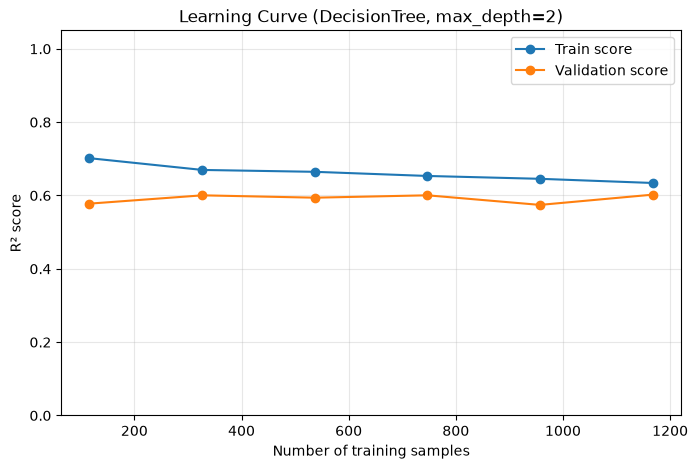

In [3]:
# TODO
# max_depth=2 결정트리의 학습곡선을 그려보세요.
model = DecisionTreeRegressor(max_depth=2, random_state=42)
train_ratio = np.linspace(0.1, 1.0, 6)

# learning_curve 실행
train_sizes, train_scores, val_scores = learning_curve(
    model, X, y,
    train_sizes = train_ratio,
    cv=5,
    n_jobs=1
)

# 각 구간별 평균 점수
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

for n, tr, va in zip(train_sizes, train_mean, val_mean):
     print(f"샘플 수 {n:4d} | Train R² = {tr:.3f} | Validation R² = {va:.3f} | 차이 = {tr - va:.3f}")

# 6. 하나의 그래프에 표시
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", label="Train score")
plt.plot(train_sizes, val_mean, "o-", label="Validation score")
plt.title("Learning Curve (DecisionTree, max_depth=2)")
plt.xlabel("Number of training samples")
plt.ylabel("R² score")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### R² : 결정계수 (설명력) - 회귀모형이 종속변수의 변동성을 얼마나 잘 설명하는지
- R² =1 : 실제값과 예측값이 일치
- R² = 0 : 실제 평균만 예측, 충분히 설명하지 못함
- R²이 1에 가까울수록 모델이 그만큼 데이터에 대한 설명력을 가지고 있다.

- 샘플 수  116 | Train R²의 평균 = 0.70 | Validation R²의 평균 = 0.57 | 차이 = 0.124
<br> -> 판단: 적은 학습데이터에서 비교적 차이가 큼 (0.124)

- 샘플 수  327 | Train R²의 평균 = 0.67 | Validation R²의 평균 = 0.60 | 차이 = 0.069
<br> -> 판단: Train데이터의 R²은 0.03감소 Validation의 R²의 0.03 상승 -> 격차가 줄어들었다.

- 샘플 수  537 | Train R²의 평균 = 0.66 | Validation R²의 평균 = 0.59 | 차이 = 0.071
<br> -> 판단: Train R²은 0.01감소 Validation R²은 0.01 감소

- 샘플 수 1168 | Train R²의 평균 = 0.63 | Validation R²의 평균 = 0.60 | 차이 = 0.032
<br> -> 판단: 평균점수 차이가 가장 낮다

- 그렇다면 이 표와 그래프를 보고 과소적합 또는 편향의 신호를 알 수 있는가?
<br> -> R²값이 Train과 Validation에서 약 0.60정도, 즉 데이터에 대한 파악이 약 60점 정도라고 보인다.

- R²값이 비교적 0.60으로 낮기 때문에 해당 데이터에 대한 충분한 파악을 하지 못한 과소적합을 의심해 볼수 있다.
<br> -> 단, R²가 0.60이면 무조건 낮다. 라는 기준이 없기 때문에 추후 다른 평가지표나 그래프를 통해 근거를 강화해야 함

- 해석: 깊이 2의 결정트리는 최대 Fold의 학습 크기 1,168개에서 Train  R²가 0.63, Validaation  R²가 0.60
- 두 점수의 차이는 1,168에서 격차가 가장 작았지만  R²이 낮아 과소적합을 의심해야 한다.

### Q1. `max_depth=2` 모델은 과소적합과 과적합 중 어느 쪽에 더 가깝다고 볼 수 있나요?

**답변:**  
<br> -> 과소적합에 더 가까움 Train과 Validation의  R²값이 모두 낮았으며 그 간격도 적었다.

## 문제 2. `max_depth=None` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=None, random_state=42)`를 만듭니다.
2. 필수 1 문제 1과 동일한 방식으로 `learning_curve()`를 사용합니다.
3. Train score와 Validation score를 그래프로 나타냅니다.
4. 두 곡선 사이의 간격을 확인합니다.

### 확인 포인트

- Train score가 매우 높은가?
- Validation score와의 간격이 크게 유지되는가?
- 고분산(과적합) 신호를 확인할 수 있는가?

샘플 수  116 | Train R² = 1.000 | Validation R² = 0.590 | 간격 = 0.410
샘플 수  327 | Train R² = 1.000 | Validation R² = 0.704 | 간격 = 0.296
샘플 수  537 | Train R² = 1.000 | Validation R² = 0.715 | 간격 = 0.285
샘플 수  747 | Train R² = 1.000 | Validation R² = 0.669 | 간격 = 0.331
샘플 수  957 | Train R² = 1.000 | Validation R² = 0.685 | 간격 = 0.315
샘플 수 1168 | Train R² = 1.000 | Validation R² = 0.727 | 간격 = 0.273


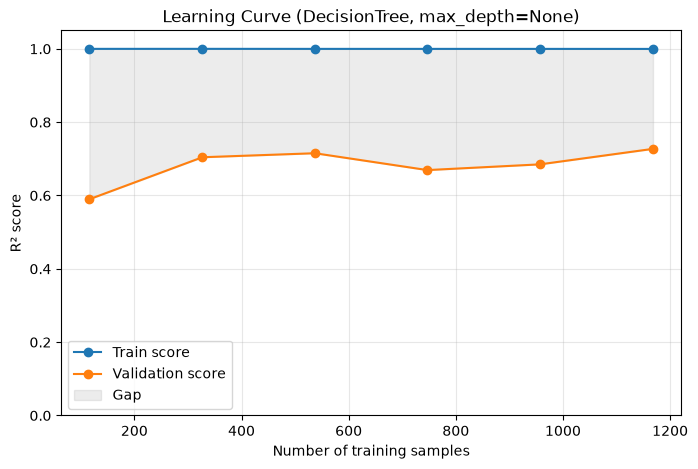

In [4]:
# TODO
# max_depth=None 결정트리의 학습곡선을 그려보세요.
# 1. 깊이 제한 없는 모델
model_deep = DecisionTreeRegressor(max_depth=None, random_state=42)

# 2. 문제 1과 동일한 방식
train_sizes_deep, train_scores_deep, val_scores_deep = learning_curve(
    model_deep, X, y,
    train_sizes=train_ratio,
    cv=5,
    n_jobs=-1
)

train_mean_deep = train_scores_deep.mean(axis=1)
val_mean_deep = val_scores_deep.mean(axis=1)

for n, tr, va in zip(train_sizes_deep, train_mean_deep, val_mean_deep):
    print(f"샘플 수 {n:4d} | Train R² = {tr:.3f} | Validation R² = {va:.3f} | 간격 = {tr - va:.3f}")

# 3. 그래프
plt.figure(figsize=(8, 5))
plt.plot(train_sizes_deep, train_mean_deep, "o-", label="Train score")
plt.plot(train_sizes_deep, val_mean_deep, "o-", label="Validation score")
# 4. 두 곡선 사이 간격 음영 표시
plt.fill_between(train_sizes_deep, val_mean_deep, train_mean_deep, alpha=0.15, color="gray", label="Gap")
plt.title("Learning Curve (DecisionTree, max_depth=None)")
plt.xlabel("Number of training samples")
plt.ylabel("R² score")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- 샘플 수  116 | Train R² = 1.000 | Validation R² = 0.590 | 간격 = 0.410
- 샘플 수  327 | Train R² = 1.000 | Validation R² = 0.704 | 간격 = 0.296
- 샘플 수  537 | Train R² = 1.000 | Validation R² = 0.715 | 간격 = 0.285
- 샘플 수 1168 | Train R² = 1.000 | Validation R² = 0.727 | 간격 = 0.273
<br> -> 해당 학습 샘플 수를 선택하여 모델링하는 것이 유리

- Train R²의 평균 0.99라는 것의 의미: 매우 작은 제곱오차로 맞추고 있다. (극소한 차이까지 맞춤)
- Train R²와 Validation R²의 차이가 0.27이라는 것의 의미:
<br> -> R²의 차이가 0.27이라고 해서 Validattion이 더 틀렸다고 해석하면 x
<br> -> Train(훈련)의 점수는 0.99점이고 Validation(검증)의 점수는 0.27로 차이가 크다는 것은 과적합의 신호

- 해석: 깊이 제한이 없는 트리 모델의 경우 Train R²이 거의 1에 가까움
<BR> 다만 Validation R²은 0.59~0.72까지 다양함
<br> 학습량 증가에 따른 Validation이 개선의 여지가 보이지만 Train R²과 Validation R² 격차를 줄이지 못해
<br> 과적합 가능성을 보고 다른 평가지표와 그래프 등을 확인해 보아야 한다.


### Q2. `max_depth=None` 모델에서 데이터를 더 추가하는 것이 도움이 될 가능성이 있는 이유는 무엇인가요?

**답변:**  
<br>과적합 상태에서는 모델이 현재 데이터를 지나치게 학습을 한 상태로 
<br> 학습 데이터가 더 많아지면 현재 학습했던 패턴 외에 패턴들을 학습 할 수가 있기 때문에
<br> Train과 Validation의 격차가 줄어들 수 있다.

---

# 필수 2. 검증곡선과 train-valid gap으로 최적 복잡도 확인

## 배경

검증곡선은 **모델의 하이퍼파라미터를 바꿔가며 Train score와 Validation score의 변화를 확인하는 그래프**입니다.

이번 문제에서는 결정트리의 `max_depth`를 바꾸어 모델 복잡도를 조절합니다.

## 문제 1. `max_depth` 검증곡선을 만드세요.

### 요구사항

1. 다음 `max_depth` 후보를 사용합니다.

```python
param_range = [1, 2, 3, 4, 5, 8, 12, 20, None]
```

2. `validation_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 각 `max_depth`의 Train score와 Validation score 평균을 계산합니다.
5. `gap = train_mean - valid_mean`을 계산합니다.
6. `max_depth`, `train`, `validation`, `gap`을 DataFrame으로 만듭니다.
7. Train / Validation score를 하나의 그래프에 표시합니다.

### 확인 포인트

- 복잡도가 증가할수록 Train score가 어떻게 변하는가?
- Validation score는 어느 지점까지 좋아지고 이후 어떻게 변하는가?
- train-valid gap은 깊이가 커질수록 어떻게 변하는가?

  max_depth  train  validation    gap
0         1  0.454       0.430  0.025
1         2  0.634       0.602  0.032
2         3  0.734       0.679  0.055
3         4  0.811       0.734  0.078
4         5  0.862       0.756  0.107
5         8  0.948       0.771  0.177
6        12  0.990       0.746  0.244
7        20  1.000       0.735  0.264
8      None  1.000       0.727  0.273


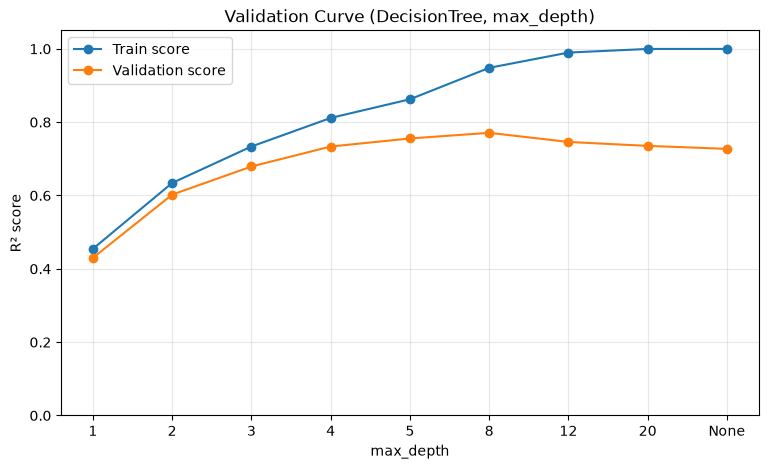

In [5]:
# TODO
# validation_curve()를 이용해 max_depth별 Train / Validation score와 gap을 확인하세요.
from sklearn.model_selection import validation_curve

# 1. max_depth 후보
param_range = [1, 2, 3, 4, 5, 8, 12, 20, None]

# 2~3. validation_curve 실행
#  - max_depth는 param_name으로 바꿀 것이므로 모델에는 넣지 않습니다
train_scores_vc, valid_scores_vc = validation_curve(
    DecisionTreeRegressor(random_state=42),
    X, y,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    n_jobs=-1
)

# 4. 평균 계산 (행 = 후보값, 열 = fold)
train_mean = train_scores_vc.mean(axis=1)
valid_mean = valid_scores_vc.mean(axis=1)

# 5. gap 계산
gap = train_mean - valid_mean

# 6. DataFrame 정리 (None이 NaN으로 바뀌지 않도록 문자열로 표시)
depth_labels = [str(d) for d in param_range]
result = pd.DataFrame({
    "max_depth": depth_labels,
    "train": train_mean,
    "validation": valid_mean,
    "gap": gap
})
print(result.round(3))

# 7. 그래프 (None은 숫자 축에 올릴 수 없으므로 위치 인덱스로 그림)
x_pos = np.arange(len(param_range))

plt.figure(figsize=(9, 5))
plt.plot(x_pos, train_mean, "o-", label="Train score")
plt.plot(x_pos, valid_mean, "o-", label="Validation score")
plt.xticks(x_pos, depth_labels)
plt.title("Validation Curve (DecisionTree, max_depth)")
plt.xlabel("max_depth")
plt.ylabel("R² score")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- 두 곡선(학습곡선과 검증 곡선)의 목적을 구분하기
- 학습곡선은 학습자료의 수를 바꾸고 검증곡선은 max_depth를 바꾼다.
- 모델결과를 유지하기 위한 핵심 조건은 학습곡선은 트리 깊이 설정, 검증곡선은 데이터와 교차검증 분할
- 학습곡선의 메인 질문 : 데이터가 늘어나면 늘어날수록 성능이 어떻게 달라지는 가?
- 검증곡선의 메인 질문 : 오차나 변동이 큰 경우 성능이 어떻게 달라지는 가? 

|max_depth| Train R² 평균 | Validation R² 평균 | gap | 진단 근거 |
| --- | ---: | ---: | ---:|---|
|1| 0.454464 | 0.429791 | 0.024674 | 두 점수 모두 상대적으로 낮음 |
|2| 0.634121 | 0.602378 | 0.031743 | 깊이 1보다 개선되지만 표현력 제한 |
|3| 0.733594 | 0.679 | 0.055 | 학습*검증이 함께 상승 |
|4| 0.811466 | 0.734 |  0.078 | 검증점수가 더 높아짐 |
|5| 0.862431 | 0.756 | 0.107 | 성능과 복잡도 균형을 검토할 수 있는 후보 |
|8| 0.948189 | 0.770884 | 0.177305 | 현재 9개 후보 중 검증 평균 최고 |
|12| 0.989787 | 0.746059 | 0.0243732 | 학습은 개선되나 검증은 하락 |
|20| 0.999686 | 0.735295 | 0.264391 | 큰 일반화 차이가 남음 |
|None| 0.999768 | 0.727192 | 0.272575 | 거의 완벽한 학습점수와 큰 gap |

- 왜 max_depth 8을 선택할 수 있을까?
<br> -> Train R²과 Validation R²이 비교적 격차가 작으며 validation R²가 가장 높은 후보를 선택
<br> -> 복잡도를 높이면 Train R²는 계속 상승하지만 Validation R²는 깊이 8에서 0.77로 가장 높고 그 이후에 감소, 깊이 1같은 경우 R²값이 Train과 Test에서 모두 낮아 과소적합을 의심해볼 수 있으며 매우 깊은 depth에서는 Train R²만 좋아져 과적합의 신호를 포착할 수 있다.
<br> -> 따라서 우선 가장 효과가 좋았던 depth 8을 검토해볼 수 있다.

### Q3. Validation score가 가장 높은 `max_depth`는 무엇인가요?

**답변:**  
- max_depth가 8이 0.77로 가장 높았다.

### Q4. `max_depth`가 매우 커질수록 train-valid gap이 커지는 이유는 무엇인가요?

**답변:**  
- 결정트리가 깊어질수록 학습 데이터의 세부적인 패턴과 노이즈까지 학습을 하려고 하기 때문에
Train은 지속적으로 높아지지만 새로운 Validate는 충분히 적응하지 못하기 때문에 유지되거나 낮아질 수 있다.

---

# 과제 1. 모델 상태를 진단하고 대응 전략 선택하기

## 배경

필수 실습에서는 학습곡선과 검증곡선을 이용해 모델의 상태를 확인했습니다.

이번 과제에서는 검증곡선 결과를 이용하여 세 가지 복잡도의 모델 상태를 직접 판단합니다.

> 과제는 필수 실습에서 확인한 결과를 해석하는 수준입니다.

## 문제

다음 세 모델을 확인하세요.

- `max_depth=1`
- `max_depth=8`
- `max_depth=None`

### 요구사항

1. 필수 2에서 만든 `gap_df`에서 세 모델의 Train score, Validation score, gap을 확인합니다.
2. 각 모델을 다음 중 하나로 진단합니다.
   - 과소적합
   - 비교적 적절한 복잡도
   - 과적합
3. 각 모델의 진단 근거를 Train score, Validation score, gap을 이용해 설명합니다.
4. 과소적합 또는 과적합 모델에 대해 교안에서 배운 대응 전략 중 적절한 방향을 하나 이상 작성합니다.

### 확인 포인트

- 점수가 낮고 gap이 작은 경우를 과소적합으로 해석할 수 있는가?
- Train score만 매우 높고 gap이 큰 경우를 과적합으로 해석할 수 있는가?
- Validation score가 높고 gap이 지나치게 크지 않은 지점을 적절한 후보로 볼 수 있는가?
- 진단 후에 대응 전략을 선택했는가?

In [ ]:
# TODO
# gap_df에서 max_depth=1, 8, None에 해당하는 결과를 확인하세요.

### Q5. 세 모델의 상태를 각각 진단하세요.

| max_depth | 진단 | 근거 |
|---|---|---|
| 1 |  |  |
| 8 |  |  |
| None |  |  |

### Q6. 과소적합 모델과 과적합 모델에 각각 어떤 대응 전략을 사용할 수 있나요?

**답변:**  
여기에 작성하세요.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 편향이 높은 모델은 일반적으로 과소적합과 과적합 중 어느 상태와 관련이 있나요?
<br> -> 편향이 높은 모델은 일반적으로 과소적합과 관련이 있다.
2. 분산이 높은 모델은 일반적으로 어느 상태와 관련이 있나요?
<br> -> 분산이 높은 모델은 일반적으로 과적합과 관련이 있다.
3. 학습곡선에서 Train과 Validation이 낮은 값에서 함께 수렴하면 어떤 상태인가요?
<br> -> 과소적합의 신호이다.
4. Train score는 매우 높지만 Validation score가 낮고 gap이 크다면 어떤 상태인가요?
<br> -> 과적합의 신호이다.
5. 검증곡선에서 Validation score가 가장 높은 지점은 어떤 의미를 가지나요?
<br> -> 현재 후보 중에서 새로운 데이터에 대한 성능이 가장 좋은, 적절한 모델 후보로 선택할 수 있다.
6. 과적합과 과소적합을 진단하지 않고 바로 처방하면 안 되는 이유는 무엇인가요?
<br> -> 과소적합과 과적합은 서로 반대되는 개념으로 과소적합 모델은 더 단순하게 설계하거나, 과적합 모델은 더 복잡하게 만들면 문제가 더 심각해 질 수 있다.
<br> -> 따라서 어떤 문제를 해결해야하는 지 명확하게 알고 대응해야 한다.